In [1]:
import numpy as np 
import pandas as pd 


In [2]:
DATAPATH= "../data/raw/fake_job_postings.csv"
df= pd.read_csv(DATAPATH)

In [4]:
df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [5]:
print(df.shape)  #no of rows and columns
print(df.columns) #name of all columns
print(df["fraudulent"].value_counts(normalize=True))
print(df["fraudulent"].value_counts(normalize=True).mul(100)) 


(17880, 18)
Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='str')
fraudulent
0    0.951566
1    0.048434
Name: proportion, dtype: float64
fraudulent
0    95.1566
1     4.8434
Name: proportion, dtype: float64


In [5]:
df.shape
df.info()
df.duplicated().sum()
df.duplicated("job_id").sum()
df["fraudulent"].isna().sum()


<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

np.int64(0)

In [6]:
df.isna().sum().sort_values(ascending=False).head(5)


salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
dtype: int64

In [7]:
df.isna().sum().sort_values(ascending=False).head(1) #columns have most missing data

salary_range    15012
dtype: int64

Here salary_range have most missing values..it may be a fraud signal but it can't prove that a job is fraudulent, we need to test whether it actually provides predictive information.

In [13]:
print(df["salary_range"].isna().mean() *100) #percentage of missing values
print(df["company_profile"].isna().mean()*100)
print(df.groupby(df["salary_range"].isna())["fraudulent"].mean()*100)
print(df.groupby(df["company_profile"].isna())["fraudulent"].mean()*100)

83.95973154362416
18.501118568232663
salary_range
False    7.775453
True     4.283240
Name: fraudulent, dtype: float64
company_profile
False     1.914631
True     17.744861
Name: fraudulent, dtype: float64


We should remove "job_id", bcz it doesn't describe the job itself..so we can keep it in original dataset but exclude it from our model's predicting features.

In [9]:
df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [10]:
df.describe()

,job_id,telecommuting,has_company_logo,has_questions,fraudulent
count,17880.000000,17880.000000,17880.000000,17880.000000,17880.000000
mean,8940.500000,0.042897,0.795302,0.491723,0.048434
std,5161.655742,0.202631,0.403492,0.499945,0.214688
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4470.750000,0.000000,1.000000,0.000000,0.000000
50%,8940.500000,0.000000,1.000000,0.000000,0.000000
75%,13410.250000,0.000000,1.000000,1.000000,0.000000
max,17880.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

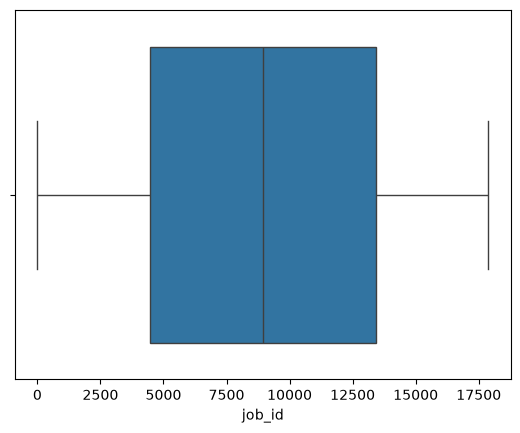

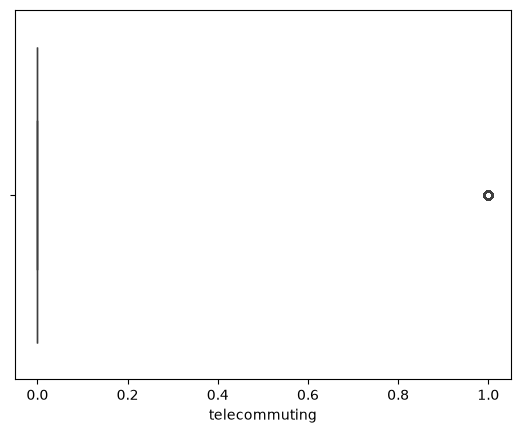

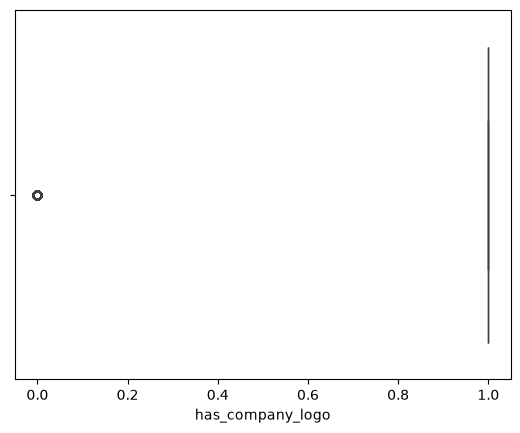

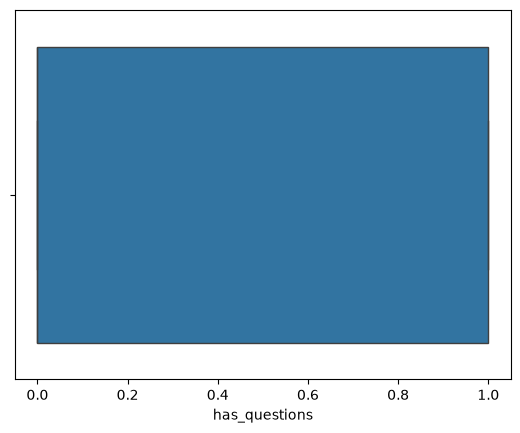

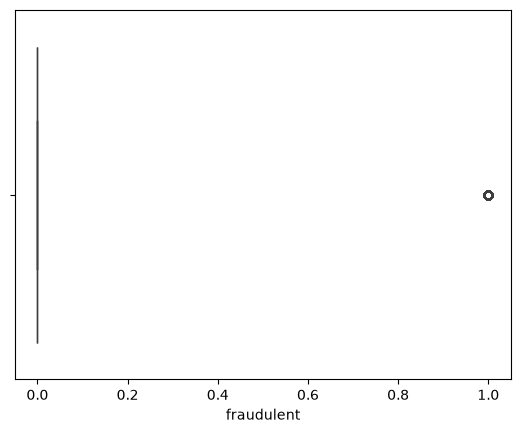

In [7]:
numerical_cols=df.select_dtypes(include=np.number).columns
for i in numerical_cols:
    sns.boxplot(x=df[i])
    plt.show()

<Axes: >

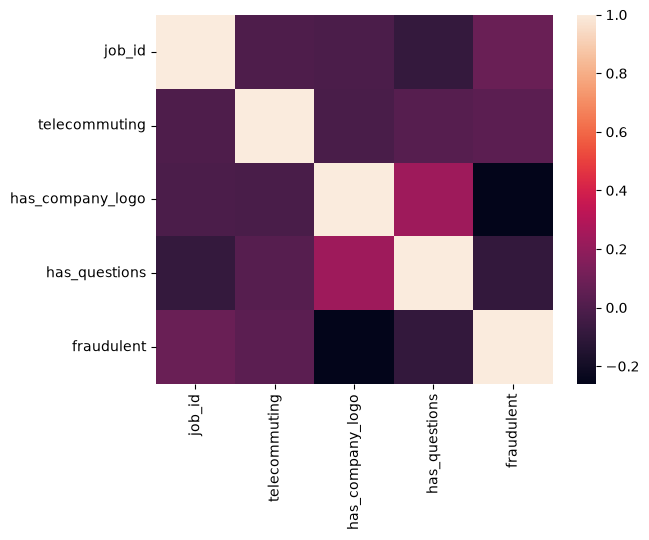

In [8]:
sns.heatmap(df.corr(numeric_only=True))

In [9]:
df.columns

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='str')

In [18]:
df["description"]

0        Food52, a fast-growing, James Beard Award-winn...
1        Organised - Focused - Vibrant - Awesome!Do you...
2        Our client, located in Houston, is actively se...
3        THE COMPANY: ESRI – Environmental Systems Rese...
4        JOB TITLE: Itemization Review ManagerLOCATION:...
                               ...                        
17875    Just in case this is the first time you’ve vis...
17876    The Payroll Accountant will focus primarily on...
17877    Experienced Project Cost Control Staff Enginee...
17878    Nemsia Studios is looking for an experienced v...
17879    Who are we?Vend is an award winning web based ...
Name: description, Length: 17880, dtype: str

In [35]:
df["description"].duplicated(False).sum()

np.int64(4268)

In [29]:
df.groupby(df["description"].isna())["fraudulent"].mean()*100

description
False      4.838078
True     100.000000
Name: fraudulent, dtype: float64

In [36]:
#counting missing descriptions
df["description"].isna().sum()

np.int64(1)

That means we've total 17880 postings, 14801 unique non-missing descriptions, 4268 rows that belongs to duplicate groups and only 1 missing descriptions

But, Is one observation really enough to establish a reliable relationship??

In [37]:
df["description"].duplicated().sum()

np.int64(3078)

In [42]:
non_missing= df[df["description"].notna()]
non_missing

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17875,17876,Account Director - Distribution,"CA, ON, Toronto",Sales,NaN,Vend is looking for some awesome new talent to...,Just in case this is the first time you’ve vis...,To ace this role you:Will eat comprehensive St...,What can you expect from us?We have an open cu...,0,1,1,Full-time,Mid-Senior level,NaN,Computer Software,Sales,0
17876,17877,Payroll Accountant,"US, PA, Philadelphia",Accounting,NaN,WebLinc is the e-commerce platform and service...,The Payroll Accountant will focus primarily on...,- B.A. or B.S. in Accounting- Desire to have f...,Health &amp; WellnessMedical planPrescription ...,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Internet,Accounting/Auditing,0
17877,17878,Project Cost Control Staff Engineer - Cost Con...,"US, TX, Houston",NaN,NaN,We Provide Full Time Permanent Positions for m...,Experienced Project Cost Control Staff Enginee...,At least 12 years professional experience.Abil...,NaN,0,0,0,Full-time,NaN,NaN,NaN,NaN,0
17878,17879,Graphic Designer,"NG, LA, Lagos",NaN,NaN,NaN,Nemsia Studios is looking for an experienced v...,1. Must be fluent in the latest versions of Co...,Competitive salary (compensation will be based...,0,0,1,Contract,Not Applicable,Professional,Graphic Design,Design,0


It means we've  3078 extra repeated occurrences like 17879-14801 will be 3078. Oh yeah our duplicated().sum() is exactly 3078.

In [25]:
df["description"].nunique()

14801

In [ ]:
copy=df.copy()

In [51]:
copy[["description","fraudulent"]]

,description,fraudulent
0,"Food52, a fast-growing, James Beard Award-winn...",0
1,Organised - Focused - Vibrant - Awesome!Do you...,0
2,"Our client, located in Houston, is actively se...",0
3,THE COMPANY: ESRI – Environmental Systems Rese...,0
4,JOB TITLE: Itemization Review ManagerLOCATION:...,0
...,...,...
17875,Just in case this is the first time you’ve vis...,0
17876,The Payroll Accountant will focus primarily on...,0
17877,Experienced Project Cost Control Staff Enginee...,0
17878,Nemsia Studios is looking for an experienced v...,0


In [54]:
audit_df=non_missing[["description","fraudulent"]].copy()
audit_df.shape

(17879, 2)

In [55]:
audit_df.isna().sum()

description    0
fraudulent     0
dtype: int64

In [58]:
audit_df["norm_description"]=audit_df["description"].str.lower()
audit_df["norm_description"]

0        food52, a fast-growing, james beard award-winn...
1        organised - focused - vibrant - awesome!do you...
2        our client, located in houston, is actively se...
3        the company: esri – environmental systems rese...
4        job title: itemization review managerlocation:...
                               ...                        
17875    just in case this is the first time you’ve vis...
17876    the payroll accountant will focus primarily on...
17877    experienced project cost control staff enginee...
17878    nemsia studios is looking for an experienced v...
17879    who are we?vend is an award winning web based ...
Name: norm_description, Length: 17879, dtype: str

In [59]:
audit_df["norm_description"]=audit_df["norm_description"].str.replace(r"\s+"," ",regex=True)

In [65]:
audit_df["norm_description"]=audit_df["norm_description"].str.strip()
audit_df[["description","norm_description"]].head(10)

,description,norm_description
0,"Food52, a fast-growing, James Beard Award-winn...","food52, a fast-growing, james beard award-winn..."
1,Organised - Focused - Vibrant - Awesome!Do you...,organised - focused - vibrant - awesome!do you...
2,"Our client, located in Houston, is actively se...","our client, located in houston, is actively se..."
3,THE COMPANY: ESRI – Environmental Systems Rese...,the company: esri – environmental systems rese...
4,JOB TITLE: Itemization Review ManagerLOCATION:...,job title: itemization review managerlocation:...
5,Job OverviewApex is an environmental consultin...,job overviewapex is an environmental consultin...
6,Your Responsibilities: Manage the English-spea...,your responsibilities: manage the english-spea...
7,Who is Airenvy?Hey there! We are seasoned entr...,who is airenvy?hey there! we are seasoned entr...
8,Implementation/Configuration/Testing/Training ...,implementation/configuration/testing/training ...
9,The Customer Service Associate will be based i...,the customer service associate will be based i...


In [68]:
(audit_df["norm_description"]=="").sum()

np.int64(1)

In [71]:
valid=audit_df[audit_df["norm_description"]!=""]
valid.nunique()

description         14800
fraudulent              2
norm_description    14591
dtype: int64

In [72]:
labels_per_description = valid.groupby("norm_description")["fraudulent"].nunique()

In [76]:
labels_per_description.head()

norm_description
"do you want to own your internet base business with no money down??"" who want`s to make money from internet home business" "do you need to own your internet base business with no money down??"you can join for free 100% and make good money with dmt instant reward at home. did you lost your job? do you need money fast?you can start earning money with us right now. this is one time in a life time chance to be your own boss. you can work with us you can earn good money with your own time, be with your family same time.for more information please contact with email or call to get start right away call (386)320-3924 thank you for reading.                                                                                                                                                                                                                                                                                                                                                     

In [88]:
grps_conflict=labels_per_description[labels_per_description > 1]
len(grps_conflict)
grps_conflict.index

Index(['workable is a product-driven software company. with thousands of enterprise users and millions in venture funding, we're building the best recruiting software in the world. a frictionless, usable, robust and highly scalable product that helps companies find and meet great people. the quality, design and usability of our software is what sets us apart from the competition. it's good to be an engineer in a company that values good engineering above all.we have a team of remarkably talented and friendly developers, a strong engineering culture and a dogged emphasis on customer-centric design. we're working on all sorts of exciting areas of application development: web, mobile, infrastructure, performance, ui/ux design, integrations with dozens of web services, api development, modern front-end frameworks, scalability, video, natural language processing, data science and usability engineering. agile methodology and test-driven development are not things we read about in blogs, it's

In [95]:

audit_df["job_id"] = non_missing["job_id"]
audit_df.head()


,description,fraudulent,norm_description,job_id
0,"Food52, a fast-growing, James Beard Award-winn...",0,"food52, a fast-growing, james beard award-winn...",1
1,Organised - Focused - Vibrant - Awesome!Do you...,0,organised - focused - vibrant - awesome!do you...,2
2,"Our client, located in Houston, is actively se...",0,"our client, located in houston, is actively se...",3
3,THE COMPANY: ESRI – Environmental Systems Rese...,0,the company: esri – environmental systems rese...,4
4,JOB TITLE: Itemization Review ManagerLOCATION:...,0,job title: itemization review managerlocation:...,5


In [101]:
conflicting= audit_df[audit_df["norm_description"].isin(grps_conflict.index)]

conflicting

,description,fraudulent,norm_description,job_id
9138,Workable is a product-driven software company....,1,workable is a product-driven software company....,9139
11889,Workable is a product-driven software company....,0,workable is a product-driven software company....,11890
15236,Workable is a product-driven software company....,0,workable is a product-driven software company....,15237


In [107]:
non_missing.columns

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='str')

In [110]:
conflicting["title"]=non_missing["title"]
conflicting["company_profile"]= non_missing["company_profile"]
conflicting["location"]=non_missing["location"]
conflicting["employment_type"]=non_missing["employment_type"]
conflicting["industry"]=non_missing["industry"]
conflicting["function"]=non_missing["function"]
conflicting

,description,fraudulent,norm_description,job_id,title,company_profile,location,employment_type,industry,function
9138,Workable is a product-driven software company....,1,workable is a product-driven software company....,9139,Front-End/JavaScript Engineer,NaN,"ID, JW, Jakarta",NaN,NaN,NaN
11889,Workable is a product-driven software company....,0,workable is a product-driven software company....,11890,Developer (Front-end team),Workable is a venture-backed startup making cl...,"GR, I, Athens",Full-time,Computer Software,Engineering
15236,Workable is a product-driven software company....,0,workable is a product-driven software company....,15237,Developer,Workable is a venture-backed startup making cl...,"GR, I, Athens",Full-time,Computer Software,Engineering


Ohkay, so we've 3078 repeated occurrence which have exact descriptions excluding first occurrence.
and there are 4268 rows which belong to exact duplicate description grps, after normalisation we identified one grp with conflicting fraud labels and that grp have three posting: 2 legitimate and 1 fraudulent


In [112]:
non_missing["function"]

0                   Marketing
1            Customer Service
2                         NaN
3                       Sales
4        Health Care Provider
                 ...         
17875                   Sales
17876     Accounting/Auditing
17877                     NaN
17878                  Design
17879             Engineering
Name: function, Length: 17879, dtype: str

In [124]:
print(non_missing["industry"].duplicated().sum())
print(non_missing.shape)
non_missing["industry"].nunique()


17747
(17879, 18)


131

In [134]:
non_missing["function"].isna().sum()

np.int64(6454)

In [130]:
non_missing["function"].value_counts().head()

function
Information Technology    1749
Sales                     1468
Engineering               1348
Customer Service          1229
Marketing                  830
Name: count, dtype: int64

In [131]:
non_missing["function"].value_counts().tail()

function
Supply Chain         36
Financial Analyst    33
Distribution         24
Purchasing           15
Science              14
Name: count, dtype: int64

In [144]:
df["industry"].isna().sum()
df["industry"].nunique()
df["industry"].value_counts().head()


industry
Information Technology and Services    1734
Computer Software                      1376
Internet                               1062
Marketing and Advertising               828
Education Management                    822
Name: count, dtype: int64